# Predicting Indonesia's CO₂ Emissions per Capita

**SDG 13: Climate Action**

### Project question
How can historical CO₂ emissions per capita data be used to predict Indonesia's future emissions?

This project uses the supplied `co2_pcap_cons.csv` dataset. It focuses on Indonesia and uses the year as the input feature and the CO₂ per capita value as the target. A Linear Regression model will be trained on earlier observations, tested on later observations, and then used to estimate the next year's value.

**Important:** A prediction is an estimate based on historical patterns. It does not prove what Indonesia's emissions will be, because future emissions can also be affected by policies, energy use, technology, economic activity, and other factors.

## 1. Import the libraries

We use:
- `pandas` to load and organise the CSV data.
- `matplotlib` to create graphs.
- `scikit-learn` to build and evaluate the Linear Regression model.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Upload and load the CSV dataset

Run this cell and select the `co2_pcap_cons.csv` file that was provided. The notebook reads the uploaded CSV directly; you do not need to type a different file path.

In [2]:
uploaded = files.upload()

# Get the name of the uploaded CSV file
file_name = next(iter(uploaded))

# Read the CSV file into a DataFrame
df = pd.read_csv(file_name)

print("File loaded:", file_name)
print("Dataset shape:", df.shape)
display(df.head())

Saving co2_pcap_cons.csv to co2_pcap_cons.csv
File loaded: co2_pcap_cons.csv
Dataset shape: (192, 225)


,geo,name,1800,1801,1802,1803,1804,1805,1806,1807,...,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
0,afg,Afghanistan,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001,...,0.280,0.253,0.262,0.245,0.247,0.254,0.261,0.261,0.279,0.284
1,ago,Angola,0.009,0.009,0.009,0.009,0.009,0.009,0.010,0.010,...,1.278,1.644,1.220,1.184,1.145,1.122,1.145,1.123,1.201,1.225
2,alb,Albania,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001,...,2.266,2.246,2.041,2.013,2.127,2.078,2.051,2.004,2.124,2.103
3,and,Andorra,0.333,0.335,0.337,0.340,0.342,0.345,0.347,0.350,...,5.902,5.833,5.971,6.073,6.268,6.120,6.058,5.631,5.969,5.909
4,are,UAE,0.063,0.063,0.064,0.064,0.064,0.064,0.065,0.065,...,26.970,26.789,26.975,26.676,23.851,23.464,21.242,19.740,20.707,21.122


## 3. Understand the dataset

The file is arranged in a wide format:
- `geo` is the country or region code.
- `name` is the country or region name.
- Each remaining column represents a year.
- The value in a year column represents the CO₂ per capita data for that country and year.

We first check the columns, data types, and missing values.

In [3]:
print("Column names:")
print(df.columns.tolist())

print("\\nDataset information:")
df.info()

print("\\nMissing values in the dataset:", df.isna().sum().sum())

Column names:
['geo', 'name', '1800', '1801', '1802', '1803', '1804', '1805', '1806', '1807', '1808', '1809', '1810', '1811', '1812', '1813', '1814', '1815', '1816', '1817', '1818', '1819', '1820', '1821', '1822', '1823', '1824', '1825', '1826', '1827', '1828', '1829', '1830', '1831', '1832', '1833', '1834', '1835', '1836', '1837', '1838', '1839', '1840', '1841', '1842', '1843', '1844', '1845', '1846', '1847', '1848', '1849', '1850', '1851', '1852', '1853', '1854', '1855', '1856', '1857', '1858', '1859', '1860', '1861', '1862', '1863', '1864', '1865', '1866', '1867', '1868', '1869', '1870', '1871', '1872', '1873', '1874', '1875', '1876', '1877', '1878', '1879', '1880', '1881', '1882', '1883', '1884', '1885', '1886', '1887', '1888', '1889', '1890', '1891', '1892', '1893', '1894', '1895', '1896', '1897', '1898', '1899', '1900', '1901', '1902', '1903', '1904', '1905', '1906', '1907', '1908', '1909', '1910', '1911', '1912', '1913', '1914', '1915', '1916', '1917', '1918', '1919', '1920', '1

## 4. Select Indonesia and prepare the data

The project focuses on Indonesia. We select its row, turn the year columns into a normal `Year` column, and keep only valid numeric observations.

This reshaping step makes the data suitable for plotting and machine learning.

In [4]:
# Find Indonesia in the country name column
indonesia = df[df["name"].astype(str).str.lower() == "indonesia"].copy()

if indonesia.empty:
    raise ValueError("Indonesia was not found in the 'name' column. Check the country names in the CSV.")

# Identify columns that contain years
year_columns = [col for col in df.columns if str(col).isdigit()]
year_columns = sorted(year_columns, key=lambda x: int(x))

# Reshape Indonesia's data from wide format to long format
indonesia_long = indonesia.melt(
    id_vars=["geo", "name"],
    value_vars=year_columns,
    var_name="Year",
    value_name="CO2_per_capita"
)

# Convert values to numeric and remove missing observations
indonesia_long["Year"] = pd.to_numeric(indonesia_long["Year"], errors="coerce")
indonesia_long["CO2_per_capita"] = pd.to_numeric(
    indonesia_long["CO2_per_capita"], errors="coerce"
)
indonesia_long = indonesia_long.dropna(subset=["Year", "CO2_per_capita"])
indonesia_long = indonesia_long.sort_values("Year").reset_index(drop=True)

print("Country:", indonesia_long["name"].iloc[0])
print("First year with data:", int(indonesia_long["Year"].min()))
print("Latest year with data:", int(indonesia_long["Year"].max()))
print("Number of observations:", len(indonesia_long))

display(indonesia_long.head())
display(indonesia_long.tail())

Country: Indonesia
First year with data: 1891
Latest year with data: 2022
Number of observations: 132


,geo,name,Year,CO2_per_capita
0,idn,Indonesia,1891,0.001
1,idn,Indonesia,1892,0.005
2,idn,Indonesia,1893,0.012
3,idn,Indonesia,1894,0.014
4,idn,Indonesia,1895,0.021


,geo,name,Year,CO2_per_capita
127,idn,Indonesia,2018,2.283
128,idn,Indonesia,2019,2.465
129,idn,Indonesia,2020,2.284
130,idn,Indonesia,2021,2.314
131,idn,Indonesia,2022,2.361


## 5. Explore Indonesia's historical CO₂ emissions per capita

The line graph shows how the recorded value changes over time. This helps us see the overall pattern before creating a prediction model.

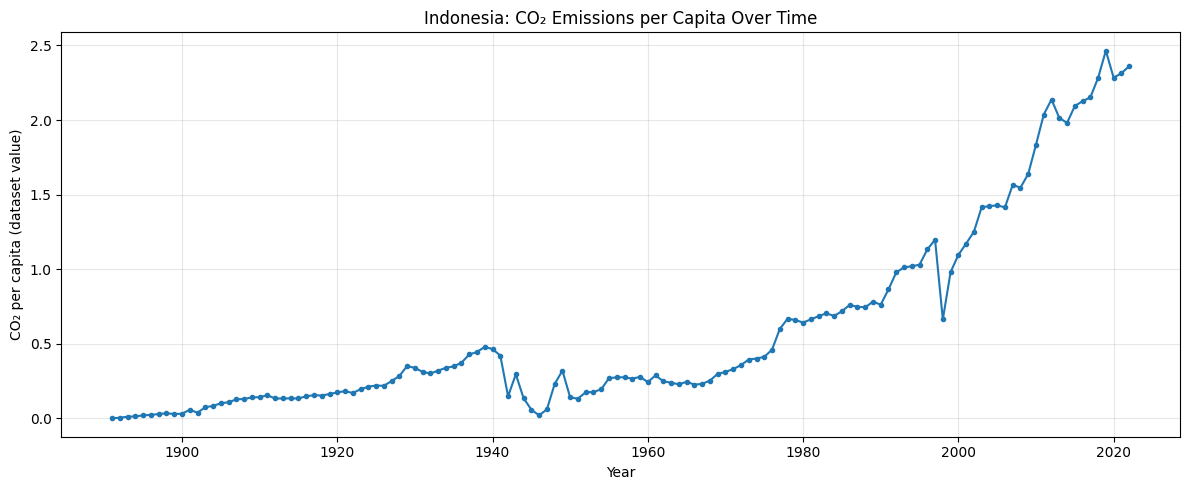

In [5]:
plt.figure(figsize=(12, 5))
plt.plot(
    indonesia_long["Year"],
    indonesia_long["CO2_per_capita"],
    marker=".",
    linewidth=1.5
)
plt.title("Indonesia: CO₂ Emissions per Capita Over Time")
plt.xlabel("Year")
plt.ylabel("CO₂ per capita (dataset value)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Prepare the features and target

For this model:
- **Feature (X):** Year
- **Target (y):** CO₂ emissions per capita

The observations are kept in chronological order. The earlier 80% of observations are used for training, while the most recent 20% are held back for testing. This is more suitable for time-based prediction than randomly mixing past and future years.

In [6]:
X = indonesia_long[["Year"]]
y = indonesia_long["CO2_per_capita"]

split_index = int(len(indonesia_long) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training years:", int(X_train["Year"].min()), "to", int(X_train["Year"].max()))
print("Testing years:", int(X_test["Year"].min()), "to", int(X_test["Year"].max()))
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training years: 1891 to 1995
Testing years: 1996 to 2022
Training observations: 105
Testing observations: 27


## 7. Train the Linear Regression model

Linear Regression finds a straight-line relationship between the year and the CO₂ per capita value. The model learns this relationship from the training data.

In [7]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Model training completed.")
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Model training completed.
Slope: 0.006801720920588845
Intercept: -12.903715177275554


## 8. Test the model and evaluate its performance

The model predicts values for the test years that it did not use during training. We compare those predictions with the actual dataset values.

We use:
- **MAE:** average absolute prediction error. Lower is better.
- **RMSE:** gives more weight to larger errors. Lower is better.
- **R²:** indicates how well the model explains variation in the test data. A value closer to 1 generally indicates a better fit; it can also be negative.

In [8]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R²): {r2:.4f}")

comparison = pd.DataFrame({
    "Year": X_test["Year"].values,
    "Actual CO2 per capita": y_test.values,
    "Predicted CO2 per capita": y_pred
})
display(comparison)

Mean Absolute Error (MAE): 0.9450
Root Mean Squared Error (RMSE): 1.0407
R-squared (R²): -3.5062


,Year,Actual CO2 per capita,Predicted CO2 per capita
0,1996,1.133,0.672520
1,1997,1.198,0.679322
2,1998,0.664,0.686123
3,1999,0.981,0.692925
4,2000,1.096,0.699727
5,2001,1.172,0.706528
6,2002,1.251,0.713330
7,2003,1.416,0.720132
8,2004,1.423,0.726934
9,2005,1.429,0.733735


## 9. Compare actual and predicted values

This graph compares the model's predictions with the actual values in the test period. A prediction line that stays close to the actual line indicates that the model has followed the test-period pattern more closely.

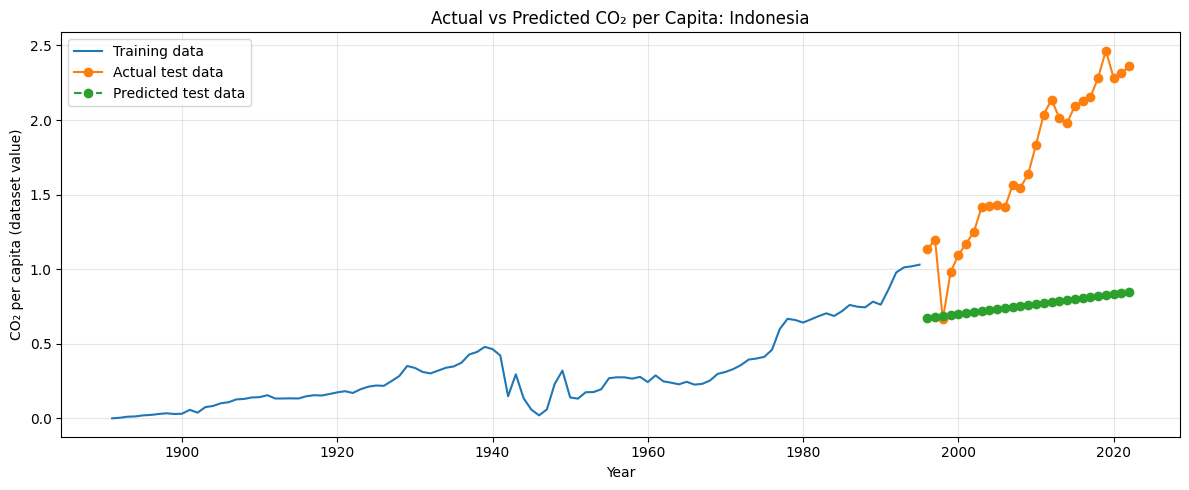

In [9]:
plt.figure(figsize=(12, 5))
plt.plot(X_train["Year"], y_train, label="Training data")
plt.plot(X_test["Year"], y_test, marker="o", label="Actual test data")
plt.plot(X_test["Year"], y_pred, marker="o", linestyle="--", label="Predicted test data")
plt.title("Actual vs Predicted CO₂ per Capita: Indonesia")
plt.xlabel("Year")
plt.ylabel("CO₂ per capita (dataset value)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Predict the next year's CO₂ emissions per capita

After evaluating the model, we fit a final Linear Regression model using all available Indonesian observations. We then use it to estimate the value for the year after the latest year in the CSV.

In [10]:
final_model = LinearRegression()
final_model.fit(X, y)

latest_year = int(indonesia_long["Year"].max())
next_year = latest_year + 1

future_year = pd.DataFrame({"Year": [next_year]})
future_prediction = final_model.predict(future_year)[0]

print(f"Latest year in dataset: {latest_year}")
print(f"Predicted CO₂ per capita for {next_year}: {future_prediction:.4f}")

Latest year in dataset: 2022
Predicted CO₂ per capita for 2023: 1.5437


In [11]:
import pickle

# Save the final model to a pickle file
with open('model.pkl', 'wb') as f:
    pickle.dump(final_model, f)

print("Model saved as model.pkl")

Model saved as model.pkl


In [12]:
app_code = """import streamlit as st
import pandas as pd
import pickle
import numpy as np

st.set_page_config(page_title=\"Indonesia CO2 Predictor\", layout=\"centered\")

st.title(\"🇮🇩 Indonesia CO₂ Emissions Predictor\")
st.write(\"This app uses a Linear Regression model trained on historical data to estimate Indonesia's future CO₂ emissions per capita (SDG 13: Climate Action).\")

# Load the saved model
try:
    with open('model.pkl', 'rb') as f:
        model = pickle.load(f)
except FileNotFoundError:
    st.error(\"Could not find 'model.pkl'. Please ensure the model file is uploaded to the repository.\")
    st.stop()

# User input for Year
year_input = st.number_input(\"Enter Year to Predict:\", min_value=1891, max_value=2100, value=2023, step=1)

if st.button(\"Predict Emissions\"):
    input_df = pd.DataFrame({\"Year\": [year_input]})
    prediction = model.predict(input_df)[0]

    st.metric(label=\"Predicted CO₂ per capita\", value=f\"{prediction:.4f} metric tons\")

    st.info(\"ℹ️ **Note:** Predictions are estimates based on linear historical patterns. Real future emissions are highly dependent on policies, economic factors, and technology changes.\")
"""

with open('app.py', 'w') as f:
    f.write(app_code)

print("Streamlit app code written to app.py")

Streamlit app code written to app.py


In [14]:
import sklearn
import pandas as pd
import numpy as np

# We will write standard, compatible versions directly into requirements.txt
requirements_content = f"""streamlit>=1.20.0
pandas=={pd.__version__}
numpy=={np.__version__}
scikit-learn=={sklearn.__version__}
"""

with open('requirements.txt', 'w') as f:
    f.write(requirements_content)

print("requirements.txt file written with the following content:")
print(requirements_content)

requirements.txt file written with the following content:
streamlit>=1.20.0
pandas==2.2.3
numpy==2.4.6
scikit-learn==1.6.1



## 11. Conclusion and connection to SDG 13

The model uses Indonesia's historical CO₂ emissions per capita data to estimate a value for the next year. The test metrics and comparison graph help us judge how well Linear Regression performed on later historical observations.

This project relates to **SDG 13: Climate Action** because monitoring CO₂ emissions can help people understand patterns connected to climate change. The prediction can be used as a simple starting point for discussion, but it should not be treated as a certain outcome or as proof that one factor causes emissions to rise or fall.

### Limitations
- The model uses only the year as an input, so it does not include factors such as population, energy sources, transport, industry, or climate policies.
- Linear Regression assumes a straight-line trend, while real emissions can rise and fall in more complex ways.
- Historical patterns may not continue into the future.
- The dataset's CO₂ per capita values are used as provided; check the original dataset source for the precise definition and unit before presenting the results.